<a href="https://colab.research.google.com/github/sanjeetkumar989159-hub/Data_wrangling-cleaning/blob/main/outliers%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("/content/hr_employee_messy_dataset.csv")

In [ ]:
df = df.dropna(subset=["Age"])

In [ ]:
df


,EmployeeID,FirstName,LastName,Age,Department,State,City,JoiningDate,YearsExperience,Salary,MaritalStatus,PerformanceRating,ManagerName,AttritionStatus,EngagementScore,WorkHoursPerWeek,Email,PhoneNumber,Gender_0,Gender_1
0,EMP04426,Juan,Harper,39.0,OPERATIONS,Tamil Nadu,Coimbatore,27-08-2021,5.2,"Rs. 97,038",divorced,5.0,Lauren Parks MD,no,NaN,42.0,juan.harper89@company.com,001-370-404-6660x5226,False,True
1,EMP01802,Tanner,Holland,24.0,marketing,Telangana,hyderabad,2019-03-22,6.8,"Rs. 84,600",divorced,2.0,Dr. Stephanie Shields,No,74.6,51.9,tanner.holland661@company.com,001-403-232-7399x7415,False,True
2,EMP01585,Dennis,Moreno,44.0,Operations,West Bengal,KOLKATA,2026-03-03,1.2,"Rs. 39,869",marreid,3.0,Peter Lewis,No,89.3,43.1,dennis.moreno338@company.com,001-477-873-0316x78719,True,False
3,EMP00245,Stephen,Martinez,24.0,SALES,Maharashtra,Pune,27 Sep 2021,5.3,77675.54,single,4.0,Adam Craig,no,NaN,43.9,stephen.martinez524@company.com,(791)755-9428x4347,False,True
4,EMP03895,Benjamin,Austin,25.0,customer support,Tamil Nadu,Chennai,2025-02-17,0.9,31978,divorced,3.0,Eric Hull,No,76.2,44.0,benjamin.austin461@company.com,412-964-0535x2932,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5375,EMP04308,Nichole,Stevens,21.0,Customer Support,Maharashtra,pune,2019-11-03,8.0,"Rs. 83,145",single,4.0,NaN,no,77.6,40.9,nichole.stevens327@company.com,001-977-918-6986x8301,True,False
5376,EMP02551,Chad,Cannon,22.0,H.R.,Tamil Nadu,Chennai,18/03/2022,6.2,"Rs. 41,369",single,2.0,Melissa Mcdonald,no,73.3,34.6,chad.cannon342@company.com,930-367-7798x367,False,True
5377,EMP00538,Cynthia,Fowler,36.0,OPERATIONS,West Bengal,durgapur,04 May 2022,4.5,34288,single,4.0,Patrick Lopez,N,81.4,48.7,cynthia.fowler778@company.com,001-782-296-3533x905,False,True
5378,EMP01221,Kathy,Hubbard,29.0,Human Resources,West Bengal,Kolkata,"January 03, 2022",4.2,42331.58,marreid,3.0,NaN,NO,75.2,39.6,kathy.hubbard877@company.com,(432)301-6290x7399,True,False


# Outliers finding


In [ ]:
def find_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(
        f"{column}: {len(outliers)} outliers found "
        f"(normal range: {lower_bound:.1f} - {upper_bound:.1f})"
    )



Age: 42 outliers found (normal range: 11.5 - 55.5)


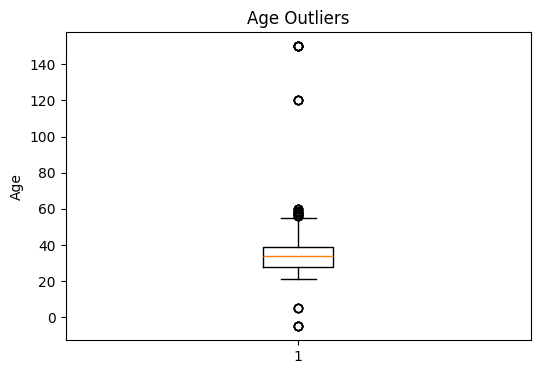

None


In [ ]:
outliers = find_outliers(df, "Age")

plt.figure(figsize=(6, 4))
plt.boxplot(df["Age"].dropna())
plt.title("Age Outliers")
plt.ylabel("Age")
plt.show()
print(outliers)

#Outliers usinf Z_scores

In [ ]:
def find_outliers_zscore(column, df, threshold=3):
    data = df[column].dropna()

    mean = data.mean()
    std = data.std()
    z_scores = (data - mean) / std

    outliers = data[abs(z_scores) > threshold]

    print(f"{column}: mean = {mean:.1f}, std = {std:.1f}")
    print(f"{column}: {len(outliers)} outliers found")

    return outliers

**THRESHOLD**
In Z-score, a threshold is a fixed limit used to determine whether a value is normal or an outlier.


In [ ]:
outliers=find_outliers_zscore('Age',df)
print(outliers)

Age: mean = 34.0, std = 9.6
Age: 23 outliers found
212     150.0
616     120.0
1245    120.0
1820     -5.0
1976      5.0
2308    120.0
2577      5.0
2803    150.0
2917    150.0
2951    150.0
2994     -5.0
3006    120.0
3495     -5.0
3643     -5.0
3751    150.0
3867    120.0
4068     -5.0
4747      5.0
4863    150.0
4984    150.0
5106      5.0
5144    150.0
5228    150.0
Name: Age, dtype: float64


**IQR** = Skewed data
**Z-score**=Normal distribution


In [ ]:
df['Age'].skew()

np.float64(3.7737492491529756)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5380 entries, 0 to 5379
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   EmployeeID         5380 non-null   object 
 1   FirstName          5380 non-null   object 
 2   LastName           5380 non-null   object 
 3   Gender             5380 non-null   object 
 4   Age                5217 non-null   float64
 5   Department         5380 non-null   object 
 6   State              5380 non-null   object 
 7   City               5380 non-null   object 
 8   JoiningDate        5380 non-null   object 
 9   YearsExperience    5275 non-null   float64
 10  Salary             5216 non-null   object 
 11  MaritalStatus      5277 non-null   object 
 12  PerformanceRating  5001 non-null   float64
 13  ManagerName        4739 non-null   object 
 14  AttritionStatus    5380 non-null   object 
 15  EngagementScore    5107 non-null   float64
 16  WorkHoursPerWeek   5380 

Fetch outlirs

In [ ]:

Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

out = df['Age'][
    (df['Age'] >= lower_bound) &
    (df['Age'] <= upper_bound)
]

print(out)
print(lower_bound)
print(upper_bound)



0       39.0
1       24.0
2       44.0
3       24.0
4       25.0
        ... 
5375    21.0
5376    22.0
5377    36.0
5378    29.0
5379    38.0
Name: Age, Length: 5175, dtype: float64
11.5
55.5


In [ ]:
out.info()

<class 'pandas.core.series.Series'>
Index: 5175 entries, 0 to 5379
Series name: Age
Non-Null Count  Dtype  
--------------  -----  
5175 non-null   float64
dtypes: float64(1)
memory usage: 80.9 KB


**Capping**

In [ ]:
df_capped=df.copy()
df_capped['Age'] = df_capped['Age'].clip(lower = lower_bound , upper=upper_bound)
df_capped['Age'].describe()

,Age
count,5217.000000
mean,33.834004
std,7.789698
min,11.500000
25%,28.000000
50%,34.000000
75%,39.000000
max,55.500000


**SQRT transformation**

In [ ]:

import numpy as np

df['Age_sqrt'] = np.sqrt(df['Age'])

print("Minimum:", df['Age_sqrt'].min())
print("Maximum:", df['Age_sqrt'].max())
print("Range:", df['Age_sqrt'].max() - df['Age_sqrt'].min())



Minimum: 2.23606797749979
Maximum: 12.24744871391589
Range: 10.0113807364161


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [ ]:
df_sqrt= df.copy()
df_sqrt['Age_sqrt'] = np.sqrt(df_sqrt['Age'])
df_sqrt[['Age','Age_sqrt']].head()
print(df_sqrt)

     EmployeeID FirstName  LastName  Gender   Age        Department  \
0      EMP04426      Juan    Harper    male  39.0        OPERATIONS   
1      EMP01802    Tanner   Holland    Male  24.0         marketing   
2      EMP01585    Dennis    Moreno  FEMALE  44.0        Operations   
3      EMP00245   Stephen  Martinez     Mle  24.0             SALES   
4      EMP03895  Benjamin    Austin       F  25.0  customer support   
...         ...       ...       ...     ...   ...               ...   
5375   EMP04308   Nichole   Stevens       F  21.0  Customer Support   
5376   EMP02551      Chad    Cannon     Mle  22.0              H.R.   
5377   EMP00538   Cynthia    Fowler    Male  36.0        OPERATIONS   
5378   EMP01221     Kathy   Hubbard  Female  29.0   Human Resources   
5379   EMP04272       Amy     Silva  Female  38.0                IT   

            State         City       JoiningDate  YearsExperience      Salary  \
0      Tamil Nadu   Coimbatore        27-08-2021              5.2 

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


**Log transformation**

In [ ]:
df_log=df.copy()
df_log.loc[df['Age']<0,'Age']=1
df_log['Age_log'] = np.log1p(df_log['Age'])
print(df_log[['Age', 'Age_log']].head(50))
df_log.isnull().sum()

     Age   Age_log
0   39.0  3.688879
1   24.0  3.218876
2   44.0  3.806662
3   24.0  3.218876
4   25.0  3.258097
5   44.0  3.806662
6   38.0  3.663562
7   33.0  3.526361
8   21.0  3.091042
9   34.0  3.555348
10  34.0  3.555348
11   NaN       NaN
12  34.0  3.555348
13  39.0  3.688879
14  28.0  3.367296
15  32.0  3.496508
16   NaN       NaN
17  21.0  3.091042
18  33.0  3.526361
19  36.0  3.610918
20  36.0  3.610918
21  30.0  3.433987
22  28.0  3.367296
23  33.0  3.526361
24  56.0  4.043051
25  58.0  4.077537
26  30.0  3.433987
27  31.0  3.465736
28  28.0  3.367296
29  41.0  3.737670
30  29.0  3.401197
31  39.0  3.688879
32  33.0  3.526361
33   NaN       NaN
34  45.0  3.828641
35  32.0  3.496508
36  23.0  3.178054
37  45.0  3.828641
38  38.0  3.663562
39  31.0  3.465736
40  32.0  3.496508
41  40.0  3.713572
42  23.0  3.178054
43  29.0  3.401197
44  31.0  3.465736
45  26.0  3.295837
46  29.0  3.401197
47  35.0  3.583519
48  30.0  3.433987
49  33.0  3.526361


,0
EmployeeID,0
FirstName,0
LastName,0
Gender,0
Age,163
Department,0
State,0
City,0
JoiningDate,0
YearsExperience,105


# **Encoding firtst technique REPLACE method**

In [ ]:
df["Gender"] = df["Gender"].str.lower().replace({
    "m": "male",
    "mle": "male",
    "f": "female",
    "femle": "female"
})
print(df['Gender'].unique())
df.columns

['male' 'female']


Index(['EmployeeID', 'FirstName', 'LastName', 'Gender', 'Age', 'Department',
       'State', 'City', 'JoiningDate', 'YearsExperience', 'Salary',
       'MaritalStatus', 'PerformanceRating', 'ManagerName', 'AttritionStatus',
       'EngagementScore', 'WorkHoursPerWeek', 'Email', 'PhoneNumber'],
      dtype='object')

# encoding Method 1

In [ ]:
df["Gender"] = df['Gender'].replace({
    "male": 1,
    "female": 0


})

/tmp/ipykernel_4684/873111189.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["Gender"] = df['Gender'].replace({


In [ ]:
df["Gender"]

,Gender
0,1
1,1
2,0
3,1
4,0
...,...
5375,0
5376,1
5377,1
5378,0


# SECOND TECHNIQUE LABLE Encoder

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["Gender"] = le.fit_transform(df["Gender"])

In [ ]:
df["Gender"]

,Gender
0,1
1,1
2,0
3,1
4,0
...,...
5375,0
5376,1
5377,1
5378,0


# One HOT encoding

In [ ]:
df = pd.get_dummies(df , columns=["Gender"])

In [ ]:
df

,EmployeeID,FirstName,LastName,Age,Department,State,City,JoiningDate,YearsExperience,Salary,MaritalStatus,PerformanceRating,ManagerName,AttritionStatus,EngagementScore,WorkHoursPerWeek,Email,PhoneNumber,Gender_0,Gender_1
0,EMP04426,Juan,Harper,39.0,OPERATIONS,Tamil Nadu,Coimbatore,27-08-2021,5.2,"Rs. 97,038",Divorced,5.0,Lauren Parks MD,no,NaN,42.0,juan.harper89@company.com,001-370-404-6660x5226,False,True
1,EMP01802,Tanner,Holland,24.0,marketing,Telangana,hyderabad,2019-03-22,6.8,"Rs. 84,600",Divorced,2.0,Dr. Stephanie Shields,No,74.6,51.9,tanner.holland661@company.com,001-403-232-7399x7415,False,True
2,EMP01585,Dennis,Moreno,44.0,Operations,West Bengal,KOLKATA,2026-03-03,1.2,"Rs. 39,869",Marreid,3.0,Peter Lewis,No,89.3,43.1,dennis.moreno338@company.com,001-477-873-0316x78719,True,False
3,EMP00245,Stephen,Martinez,24.0,SALES,Maharashtra,Pune,27 Sep 2021,5.3,77675.54,single,4.0,Adam Craig,no,NaN,43.9,stephen.martinez524@company.com,(791)755-9428x4347,False,True
4,EMP03895,Benjamin,Austin,25.0,customer support,Tamil Nadu,Chennai,2025-02-17,0.9,31978,DIVORCED,3.0,Eric Hull,No,76.2,44.0,benjamin.austin461@company.com,412-964-0535x2932,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5375,EMP04308,Nichole,Stevens,21.0,Customer Support,Maharashtra,pune,2019-11-03,8.0,"Rs. 83,145",Single,4.0,NaN,no,77.6,40.9,nichole.stevens327@company.com,001-977-918-6986x8301,True,False
5376,EMP02551,Chad,Cannon,22.0,H.R.,Tamil Nadu,Chennai,18/03/2022,6.2,"Rs. 41,369",SINGLE,2.0,Melissa Mcdonald,no,73.3,34.6,chad.cannon342@company.com,930-367-7798x367,False,True
5377,EMP00538,Cynthia,Fowler,36.0,OPERATIONS,West Bengal,durgapur,04 May 2022,4.5,34288,single,4.0,Patrick Lopez,N,81.4,48.7,cynthia.fowler778@company.com,001-782-296-3533x905,False,True
5378,EMP01221,Kathy,Hubbard,29.0,Human Resources,West Bengal,Kolkata,"January 03, 2022",4.2,42331.58,Marreid,3.0,NaN,NO,75.2,39.6,kathy.hubbard877@company.com,(432)301-6290x7399,True,False


In [ ]:
df["MaritalStatus"]

,MaritalStatus
0,Divorced
1,Divorced
2,Marreid
3,single
4,DIVORCED
...,...
5375,Single
5376,SINGLE
5377,single
5378,Marreid


In [ ]:
df["MaritalStatus"] = df["MaritalStatus"].str.lower().replace({
    "DIVORCED	": "Divorced	",
    "SINGLE	": "single",
    "Sngle": "single"
})
print(df['MaritalStatus'].unique())
df.columns

['divorced' 'marreid' 'single' 'married' nan 'sngle' '-' 'unknown']


Index(['EmployeeID', 'FirstName', 'LastName', 'Age', 'Department', 'State',
       'City', 'JoiningDate', 'YearsExperience', 'Salary', 'MaritalStatus',
       'PerformanceRating', 'ManagerName', 'AttritionStatus',
       'EngagementScore', 'WorkHoursPerWeek', 'Email', 'PhoneNumber',
       'Gender_0', 'Gender_1'],
      dtype='object')

In [ ]:
df["MaritalStatus"]

,MaritalStatus
0,divorced
1,divorced
2,marreid
3,single
4,divorced
...,...
5375,single
5376,single
5377,single
5378,marreid


In [ ]:
df


,EmployeeID,FirstName,LastName,Age,Department,State,City,JoiningDate,YearsExperience,Salary,MaritalStatus,PerformanceRating,ManagerName,AttritionStatus,EngagementScore,WorkHoursPerWeek,Email,PhoneNumber,Gender_0,Gender_1
0,EMP04426,Juan,Harper,39.0,OPERATIONS,Tamil Nadu,Coimbatore,27-08-2021,5.2,"Rs. 97,038",divorced,5.0,Lauren Parks MD,no,NaN,42.0,juan.harper89@company.com,001-370-404-6660x5226,False,True
1,EMP01802,Tanner,Holland,24.0,marketing,Telangana,hyderabad,2019-03-22,6.8,"Rs. 84,600",divorced,2.0,Dr. Stephanie Shields,No,74.6,51.9,tanner.holland661@company.com,001-403-232-7399x7415,False,True
2,EMP01585,Dennis,Moreno,44.0,Operations,West Bengal,KOLKATA,2026-03-03,1.2,"Rs. 39,869",marreid,3.0,Peter Lewis,No,89.3,43.1,dennis.moreno338@company.com,001-477-873-0316x78719,True,False
3,EMP00245,Stephen,Martinez,24.0,SALES,Maharashtra,Pune,27 Sep 2021,5.3,77675.54,single,4.0,Adam Craig,no,NaN,43.9,stephen.martinez524@company.com,(791)755-9428x4347,False,True
4,EMP03895,Benjamin,Austin,25.0,customer support,Tamil Nadu,Chennai,2025-02-17,0.9,31978,divorced,3.0,Eric Hull,No,76.2,44.0,benjamin.austin461@company.com,412-964-0535x2932,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5375,EMP04308,Nichole,Stevens,21.0,Customer Support,Maharashtra,pune,2019-11-03,8.0,"Rs. 83,145",single,4.0,NaN,no,77.6,40.9,nichole.stevens327@company.com,001-977-918-6986x8301,True,False
5376,EMP02551,Chad,Cannon,22.0,H.R.,Tamil Nadu,Chennai,18/03/2022,6.2,"Rs. 41,369",single,2.0,Melissa Mcdonald,no,73.3,34.6,chad.cannon342@company.com,930-367-7798x367,False,True
5377,EMP00538,Cynthia,Fowler,36.0,OPERATIONS,West Bengal,durgapur,04 May 2022,4.5,34288,single,4.0,Patrick Lopez,N,81.4,48.7,cynthia.fowler778@company.com,001-782-296-3533x905,False,True
5378,EMP01221,Kathy,Hubbard,29.0,Human Resources,West Bengal,Kolkata,"January 03, 2022",4.2,42331.58,marreid,3.0,NaN,NO,75.2,39.6,kathy.hubbard877@company.com,(432)301-6290x7399,True,False


In [ ]:
Q1 = df[Salary].quantile(0.25)
Q3 = df[Salary].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask |= (df[col] < lower) | (df[col] > upper)

df_outliers = df[outlier_mask]

print(df_outliers)

